In [2]:
from scipy import stats
import pandas as pd
import matplotlib.pyplot as plt
import scikit_posthocs as sp

In [3]:
df_rfm = pd.read_csv('RFM_base.csv')
df_monthly = pd.read_csv('agg_m.csv')
df_i = pd.read_csv('agg_i.csv')

In [4]:
# RFM

# R - Recency (давность покупки), F - Frequency (частота покупок), M - Monetary (сумма покупок)

labels_r = [5, 4, 3, 2, 1]
labels_m = [1, 2, 3, 4, 5]

df_rfm['R_score'] = pd.qcut(
    df_rfm['R'],
    q=5,
    labels=labels_r
)

df_rfm['F_score'] = pd.qcut(
    df_rfm['F'],
    q=5,
    labels=False,
    duplicates='drop'
) + 1

df_rfm['M_score'] = pd.qcut(
    df_rfm['M'],
    q=5,
    labels=labels_m
)

df_rfm['RFM_score'] = (
    df_rfm['R_score'].astype(str) +
    df_rfm['F_score'].astype(str) +
    df_rfm['M_score'].astype(str)
)

def segment(x):
    r, f, m = x['R_score'], x['F_score'], x['M_score']
    if r >= 4 and f >= 4 and m >= 4:
        return 'Лояльные'
    elif r <= 2 and f >= 4 and m >= 4:
        return 'В зоне оттока'
    elif r >= 4 and f <= 2:
        return 'Новые'
    elif r <= 2 and f <= 2 and m <= 2:
        return 'Потерянные'
    else:
        return 'Прочие'

df_rfm['Segment'] = df_rfm.apply(segment, axis=1)

df_rfm.head()

,Customer ID,R,F,M,R_score,F_score,M_score,RFM_score,Segment
0,12346.0,325,12,77556.46,2,4,5,245,В зоне оттока
1,12347.0,1,8,5633.32,5,3,5,535,Прочие
2,12348.0,74,5,2019.40,3,3,4,334,Прочие
3,12349.0,18,4,4428.69,5,2,5,525,Новые
4,12350.0,309,1,334.40,2,1,2,212,Потерянные


In [5]:
segments = df_rfm.groupby('Segment').agg(
    Count=('Customer ID', 'count'),
    AVG_R=('R', 'mean'),
    AVG_F=('F', 'mean'),
    AVG_M=('M', 'mean'),
    Total_M=('M', 'sum')
).round(1).reset_index()

segments['Revenue_Share_%'] = (
    segments['Total_M']/df_rfm['M'].sum()*100
).round(1)

segments['Count_Share_%'] = (
    segments['Count']/segments['Count'].sum()*100
).round(1)
segments = segments.sort_values('Count_Share_%', ascending=False)
segments.head(50)

# Прочие = 43,9% - самый крупный сегмент, по сути "мусорная корзина" для тех, кто не попал под чёткие правила.
# Соответственно, лучше ввести подсегменты внутри "Прочих"

,Segment,Count,AVG_R,AVG_F,AVG_M,Total_M,Revenue_Share_%,Count_Share_%
4,Прочие,2521,176.8,4.8,1931.8,4870145.4,27.4,42.9
3,Потерянные,1469,457.9,1.4,276.8,406613.6,2.3,25.0
2,Новые,951,25.6,2.4,1010.1,960650.1,5.4,16.2
1,Лояльные,875,16.8,22.3,12494.4,10932570.4,61.6,14.9
0,В зоне оттока,62,326.5,17.0,9249.2,573449.7,3.2,1.1


In [6]:
def segment(row):
    r, f, m = row['R_score'], row['F_score'], row['M_score']
    
    if r >= 4 and f >= 4 and m >= 4:
        return 'Лояльные'
    elif r <= 2 and f >= 4 and m >= 4:
        return 'В зоне оттока'
    elif r <= 2 and f >= 3 and m >= 3:
        return 'Уходящие'
    elif r >= 4 and f <= 2 and m >= 3:
        return 'Новые с высоким чеком'
    elif r >= 4 and f <= 2:
        return 'Новые'
    elif r <= 2 and f <= 2 and m <= 2:
        return 'Потерянные'
    elif f >= 4 and m <= 2:
        return 'Частые с низким чеком'
    elif r == 3 and f == 3 and m == 3:
        return 'Стабильные средние'
    else:
        return 'Прочие'

df_rfm['Segment'] = df_rfm.apply(segment, axis=1)

segments = df_rfm.groupby('Segment').agg(
    Count=('Customer ID', 'count'),
    AVG_R=('R', 'mean'),
    AVG_F=('F', 'mean'),
    AVG_M=('M', 'mean'),
    Total_M=('M', 'sum')
).round(1).reset_index()

segments['Revenue_Share_%'] = (
    segments['Total_M']/df_rfm['M'].sum()*100
).round(1)

segments['Count_Share_%'] = (
    segments['Count']/segments['Count'].sum()*100
).round(1)

segments = segments.sort_values('Count_Share_%', ascending=False)

segments.head(40)

,Segment,Count,AVG_R,AVG_F,AVG_M,Total_M,Revenue_Share_%,Count_Share_%
5,Прочие,2253,163.4,4.6,1931.5,4351566.8,24.5,38.3
4,Потерянные,1469,457.9,1.4,276.8,406613.6,2.3,25.0
1,Лояльные,875,16.8,22.3,12494.4,10932570.4,61.6,14.9
3,Новые с высоким чеком,484,24.7,3.0,1667.4,807007.6,4.5,8.2
2,Новые,467,26.4,1.8,329.0,153642.5,0.9,7.9
7,Уходящие,206,340.6,6.1,2230.8,459547.5,2.6,3.5
0,В зоне оттока,62,326.5,17.0,9249.2,573449.7,3.2,1.1
6,Стабильные средние,59,117.3,5.7,979.7,57802.6,0.3,1.0
8,Частые с низким чеком,3,105.7,12.7,409.5,1228.6,0.0,0.1


In [7]:
# Статистика

group_df_i = df_i.groupby('Country').agg(
    Count=('Invoice', 'count')
).reset_index()
group_df_i['Rank'] = group_df_i['Count'].rank(method='first', ascending=False)

group_df_i = group_df_i.sort_values('Rank')
group_df_i = (
    group_df_i[group_df_i['Rank'] <= 6]
)

group_df_i.head(50)

,Country,Count,Rank
40,United Kingdom,38401,1.0
15,Germany,789,2.0
11,EIRE,626,3.0
14,France,622,4.0
26,Netherlands,229,5.0
34,Spain,154,6.0


In [8]:
countries = ['United Kingdom', 'Germany', 'EIRE', 'France', 'Netherlands', 'Spain']

df_i_filtered = df_i[df_i['Country'].isin(countries)].copy()

# Отрицательная выручка на уровне счёта
negative_revenue = df_i_filtered[df_i_filtered['Revenue'] < 0]
print('Количество счетов с отрицательной выручкой:', len(negative_revenue))

# Исключаем счета с отрицательной выручкой — это не реальные продажи,
# а служебные корректировки с отрицательной ценой при положительном количестве
df_i_filtered_clean = df_i_filtered[df_i_filtered['Revenue'] > 0].copy()

print(f'Исключено счетов: {len(df_i_filtered) - len(df_i_filtered_clean)}')

uk = df_i_filtered_clean[df_i_filtered_clean['Country'] == 'United Kingdom']['Revenue']
germany = df_i_filtered_clean[df_i_filtered_clean['Country'] == 'Germany']['Revenue']
france = df_i_filtered_clean[df_i_filtered_clean['Country'] == 'France']['Revenue']
eire = df_i_filtered_clean[df_i_filtered_clean['Country'] == 'EIRE']['Revenue']
spain = df_i_filtered_clean[df_i_filtered_clean['Country'] == 'Spain']['Revenue']
netherlands = df_i_filtered_clean[df_i_filtered_clean['Country'] == 'Netherlands']['Revenue']

Количество счетов с отрицательной выручкой: 5
Исключено счетов: 1866


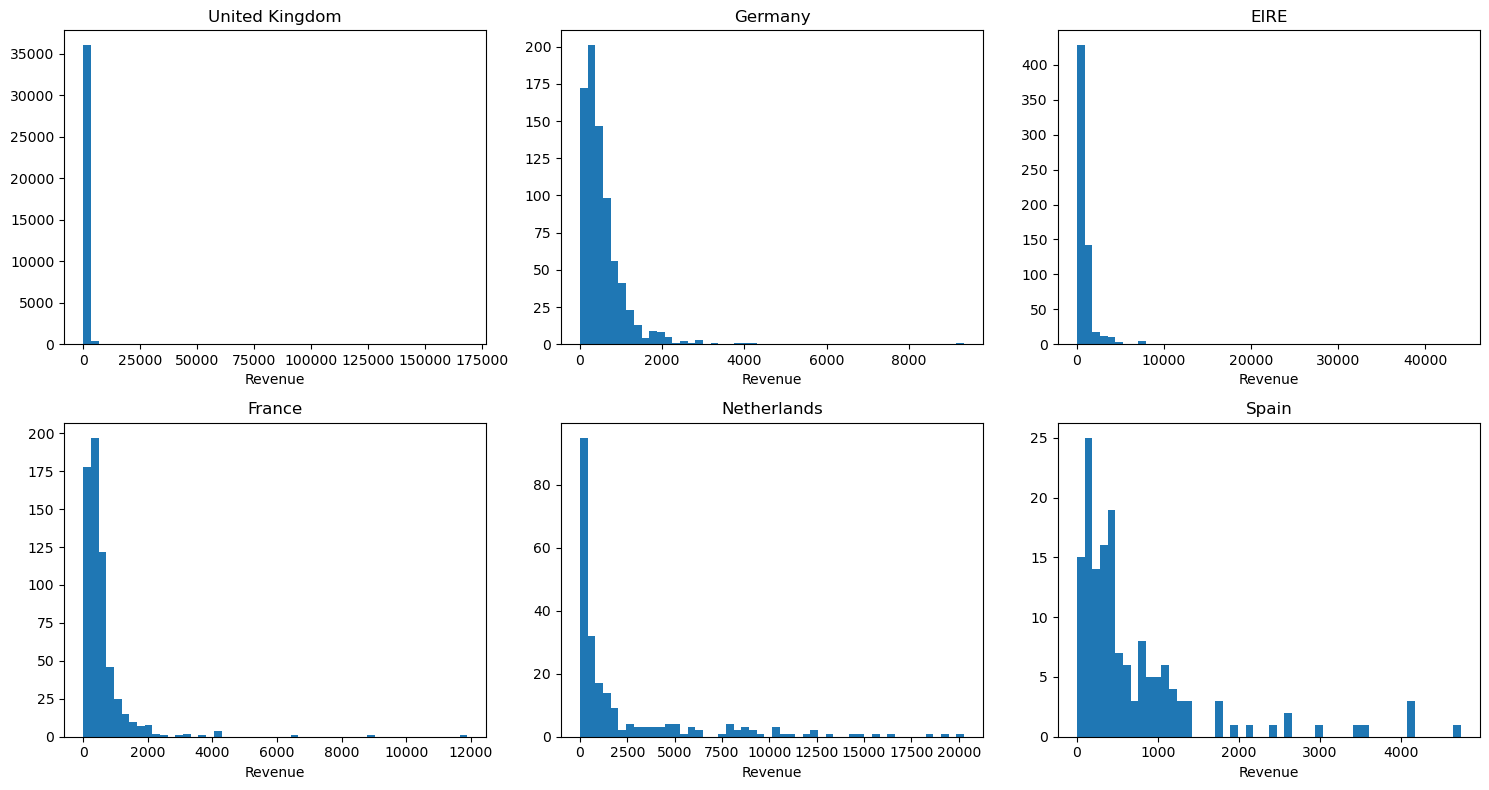

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, country in enumerate(countries):
    data = df_i_filtered_clean[df_i_filtered_clean['Country'] == country]['Revenue']
    axes[i].hist(data, bins=50)
    axes[i].set_title(country)
    axes[i].set_xlabel('Revenue')

plt.tight_layout()
plt.show()

In [10]:
df_i_filtered_clean.sort_values('Revenue', ascending=False).head()

,Country,Invoice,Revenue
41908,United Kingdom,581483,168469.60
23418,United Kingdom,541431,77183.60
38801,United Kingdom,574941,52940.94
39470,United Kingdom,576365,50653.91
19717,United Kingdom,533027,49844.99


In [11]:
df_i_filtered_clean.loc[41908]

Country    United Kingdom
Invoice            581483
Revenue          168469.6
Name: 41908, dtype: object

In [12]:
# Строка с аномальным количеством (80 995 шт. одного товара
# PAPER CRAFT, LITTLE BIRDIE в одном счёте)
# похожа на ошибку ввода данных, а не на легитимный опт —
# исключаю этот счёт из анализа по странам
anomaly_invoice = '581483'

df_i_filtered_clean = df_i_filtered_clean[df_i_filtered_clean['Invoice'] != anomaly_invoice]

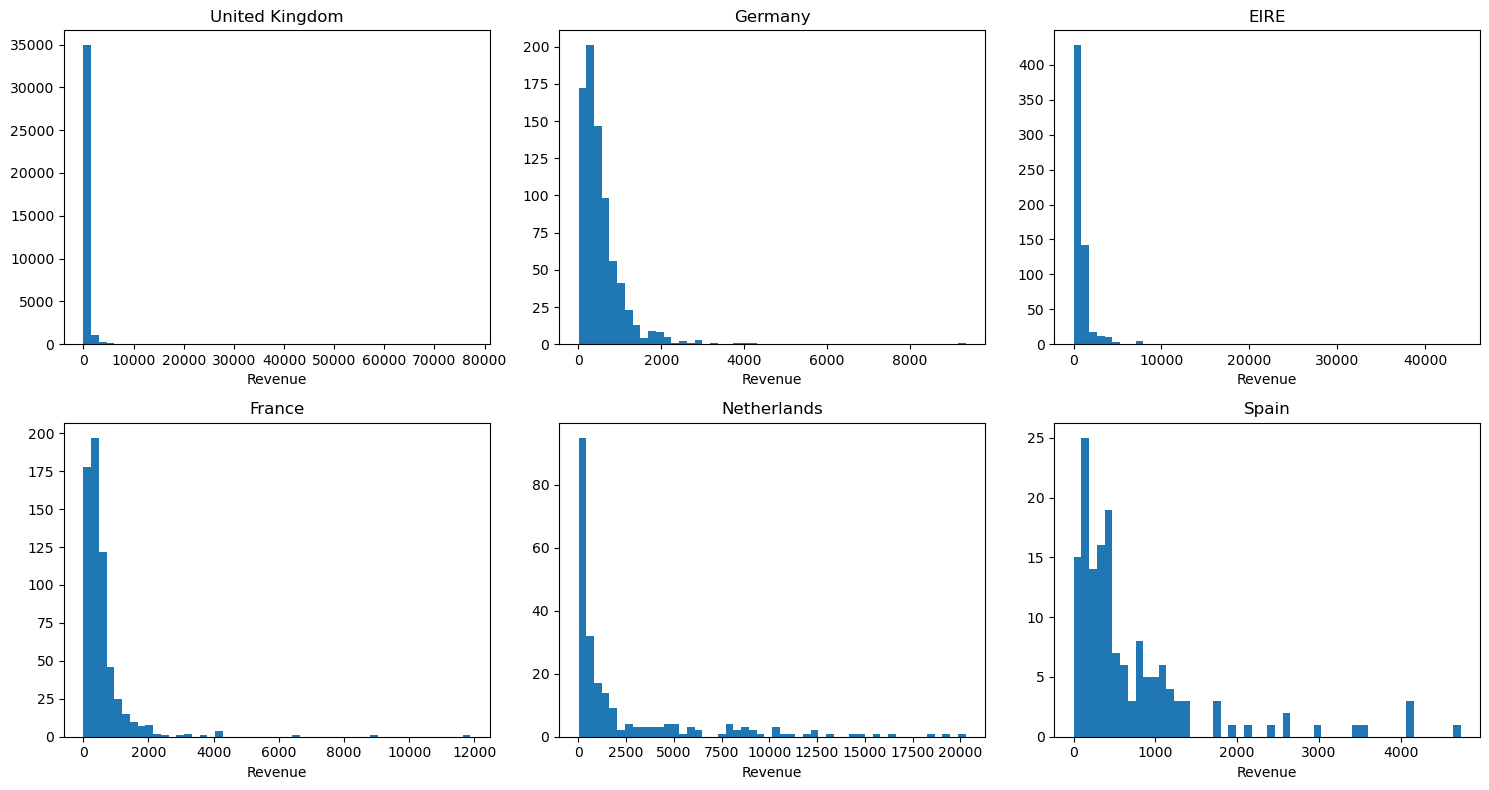

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, country in enumerate(countries):
    data = df_i_filtered_clean[df_i_filtered_clean['Country'] == country]['Revenue']
    axes[i].hist(data, bins=50)
    axes[i].set_title(country)
    axes[i].set_xlabel('Revenue')

plt.tight_layout()
plt.show()

In [14]:
result_levene = stats.levene(uk, germany, france, eire, spain, netherlands)

print('statistic:', result_levene.statistic)
print('pvalue:', result_levene.pvalue)

statistic: 80.54968331339167
pvalue: 2.100408462110415e-84


In [15]:
# H0: медиана одинакова во всех сравниваемых странах.
# H1: хотя бы в одной стране медиана статистически значимо отличается.

result_kruskal = stats.kruskal(uk, germany, france, eire, spain, netherlands)

print('Kruskal-Wallis statistic:', result_kruskal.statistic)
print('Kruskal-Wallis pvalue:', result_kruskal.pvalue)

Kruskal-Wallis statistic: 630.4850345294523
Kruskal-Wallis pvalue: 5.2276933573130675e-134


In [16]:
# тест Данна

result_dunn = sp.posthoc_dunn(
    df_i_filtered_clean,
    val_col='Revenue',
    group_col='Country',
    p_adjust='bonferroni'
)

result_dunn

,EIRE,France,Germany,Netherlands,Spain,United Kingdom
EIRE,1.000000e+00,1.105383e-13,1.332651e-15,1.070089e-01,0.000159,8.595823e-85
France,1.105383e-13,1.000000e+00,1.000000e+00,4.055188e-02,1.000000,5.031661e-17
Germany,1.332651e-15,1.000000e+00,1.000000e+00,2.416243e-02,1.000000,8.238657e-21
Netherlands,1.070089e-01,4.055188e-02,2.416243e-02,1.000000e+00,1.000000,2.235823e-17
Spain,1.590190e-04,1.000000e+00,1.000000e+00,1.000000e+00,1.000000,1.417848e-05
United Kingdom,8.595823e-85,5.031661e-17,8.238657e-21,2.235823e-17,0.000014,1.000000e+00


In [17]:
country_stats = (
    df_i_filtered_clean
    .groupby('Country')['Revenue']
    .agg(
        Median_Revenue='median',
        Mean_Revenue='mean',
        Count='count'
    ).reset_index()
)

country_stats.head(10)

,Country,Median_Revenue,Mean_Revenue,Count
0,EIRE,696.430,1061.392620,626
1,France,392.145,573.865916,622
2,Germany,392.880,546.593740,789
3,Netherlands,607.190,2430.843596,228
4,Spain,432.890,708.951494,154
5,United Kingdom,300.410,484.545826,36535


In [18]:
# ТРЕНД

# Убираю 2011 12, т.к. данные всего за 9 дней в этом месяце.

df_monthly = df_monthly.query('Date < "2011-12"')

df_y_m = df_monthly.copy()

df_y_m = df_monthly.assign(
    Year=df_monthly['Date'].str[0:4].astype(int),
    Month=df_monthly['Date'].str[5:7].astype(int)
)

df_y_m = df_y_m.drop(columns=['Date'])

df_y_m.head(50)

,Revenue,Year,Month
0,825685.760,2009,12
1,652708.502,2010,1
2,553713.306,2010,2
3,833570.131,2010,3
4,627934.632,2010,4
5,659858.860,2010,5
6,752270.140,2010,6
7,606681.150,2010,7
8,697274.910,2010,8
9,924333.011,2010,9


In [19]:
comparison = df_y_m[df_y_m['Year'].isin([2010, 2011])].pivot_table(
    index='Month',
    columns='Year',
    values='Revenue'
)

comparison['Growth_%'] = (
    (comparison[2011] - comparison[2010])
    / comparison[2010] * 100
).round(2)

comparison.head(50)

Year,2010,2011,Growth_%
Month,,,
1,652708.502,691364.560,5.92
2,553713.306,523631.890,-5.43
3,833570.131,717639.360,-13.91
4,627934.632,537808.621,-14.35
5,659858.860,770536.020,16.77
6,752270.140,761739.900,1.26
7,606681.150,719221.191,18.55
8,697274.910,737014.260,5.70
9,924333.011,1058590.172,14.52


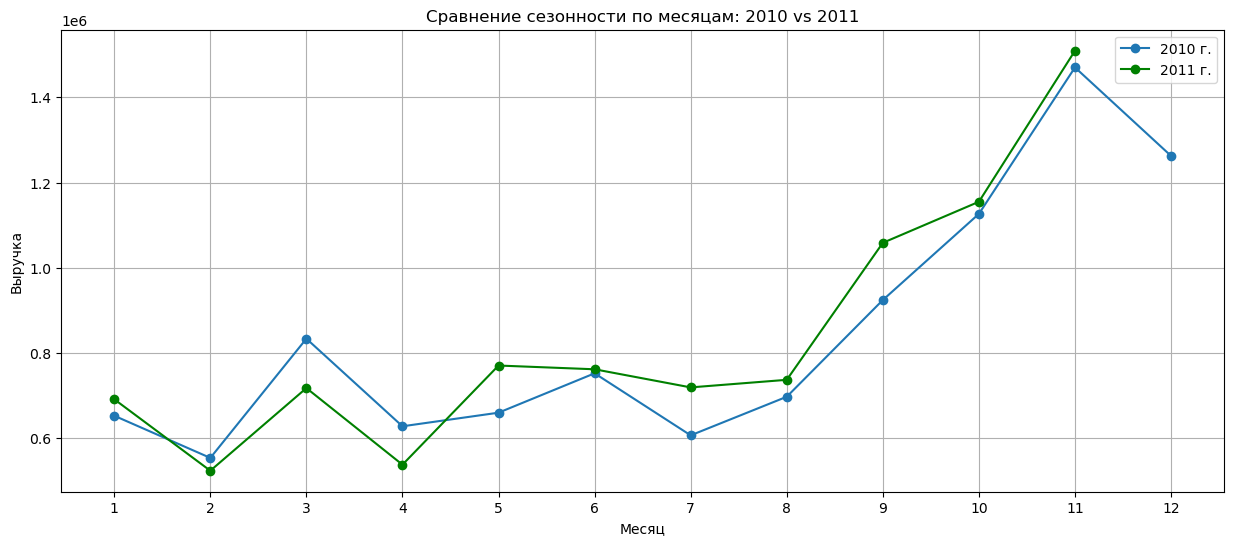

In [20]:
df_year_2010 = df_y_m[df_y_m['Year'] == 2010].copy()
df_year_2011 = df_y_m[df_y_m['Year'] == 2011].copy()

plt.figure(figsize=(15, 6))
plt.plot(df_year_2010['Month'], df_year_2010['Revenue'], marker='o', label='2010 г.')
plt.plot(df_year_2011['Month'], df_year_2011['Revenue'], marker='o', label='2011 г.', color='green')
plt.xticks(range(1, 13))
plt.legend()
plt.title('Сравнение сезонности по месяцам: 2010 vs 2011')
plt.xlabel('Месяц')
plt.ylabel('Выручка')
plt.grid()
plt.show()

In [21]:
# df_y_m.to_csv('trend.csv', index=False)

In [22]:
# segments.to_csv('segment.csv', index=False)

In [23]:
# country_stats.to_csv('country_stats.csv', index=False)

In [24]:
# df_i_filtered_clean.to_csv('df_i_filtered_clean.csv', index=False)

In [25]:
# df_rfm.to_csv('rfm.csv', index=False)